In [ ]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive
drive.mount("/content/drive")

# Create project folder
project_path = Path("/content/drive/MyDrive/RideOpt_AI_v2")
project_path.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_path)
print("Setup completed!")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/RideOpt_AI_v2
Setup completed!


In [ ]:
import requests

# Official NYC taxi dataset
url = "https://d37ci6vzurychx.cloudfront.net/trip-data/fhvhv_tripdata_2025-01.parquet"

# Save original data permanently to Google Drive
data_file = project_path / "fhvhv_tripdata_2025-01.parquet"

if data_file.exists():
    print("Dataset already downloaded!")
else:
    temp_file = project_path / "download.part"

    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()

        with open(temp_file, "wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)

    temp_file.rename(data_file)
    print("Dataset downloaded successfully!")

print("File size:", round(data_file.stat().st_size / 1024**2, 2), "MB")
print("Saved in Google Drive:", data_file.exists())

Dataset downloaded successfully!
File size: 468.33 MB
Saved in Google Drive: True


In [ ]:
import pyarrow.parquet as pq

# Read dataset information without loading all trips
parquet_file = pq.ParquetFile(data_file)

print("Total trips:", parquet_file.metadata.num_rows)
print("Total columns:", len(parquet_file.schema.names))

print("\nColumn names:")
print(parquet_file.schema.names)

# Display only 5 sample rows
sample = next(parquet_file.iter_batches(batch_size=5)).to_pandas()

print("\nFirst 5 rows:")
display(sample)

Total trips: 20405666
Total columns: 25

Column names:
['hvfhs_license_num', 'dispatching_base_num', 'originating_base_num', 'request_datetime', 'on_scene_datetime', 'pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID', 'trip_miles', 'trip_time', 'base_passenger_fare', 'tolls', 'bcf', 'sales_tax', 'congestion_surcharge', 'airport_fee', 'tips', 'driver_pay', 'shared_request_flag', 'shared_match_flag', 'access_a_ride_flag', 'wav_request_flag', 'wav_match_flag', 'cbd_congestion_fee']

First 5 rows:


,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,congestion_surcharge,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag,cbd_congestion_fee
0,HV0003,B03404,B03404,2025-01-01 00:28:07,2025-01-01 00:31:17,2025-01-01 00:33:25,2025-01-01 00:54:24,148,211,1.320,...,2.75,0.0,0.0,15.71,N,N,N,N,N,0.0
1,HV0005,B03406,None,2025-01-01 00:18:33,NaT,2025-01-01 00:29:49,2025-01-01 00:41:52,127,244,3.313,...,0.00,0.0,0.0,23.57,N,N,N,N,N,0.0
2,HV0003,B03404,B03404,2025-01-01 00:28:22,2025-01-01 00:31:52,2025-01-01 00:32:39,2025-01-01 01:20:33,132,181,13.430,...,0.00,2.5,0.0,47.75,N,N,N,N,N,0.0
3,HV0003,B03404,B03404,2025-01-01 00:27:13,2025-01-01 00:33:58,2025-01-01 00:34:55,2025-01-01 00:39:19,76,76,0.820,...,0.00,0.0,0.0,12.20,N,N,N,N,N,0.0
4,HV0003,B03404,B03404,2025-01-01 00:33:29,2025-01-01 00:45:46,2025-01-01 00:46:19,2025-01-01 00:53:56,76,76,1.610,...,0.00,0.0,0.0,17.67,N,N,N,N,N,0.0


In [ ]:
%pip install -q duckdb

import duckdb

# Check data quality using only the required columns
result = duckdb.sql(f"""
    SELECT
        COUNT(*) AS total_trips,
        COUNT(*) - COUNT(pickup_datetime) AS missing_pickup_time,
        COUNT(*) - COUNT(PULocationID) AS missing_zone,
        COUNT(*) FILTER (
            WHERE pickup_datetime < '2025-01-01'
               OR pickup_datetime >= '2025-02-01'
        ) AS trips_outside_january
    FROM read_parquet('{data_file}')
""").df()

display(result)

,total_trips,missing_pickup_time,missing_zone,trips_outside_january
0,20405666,0,0,0


In [ ]:
# Download NYC taxi zone names
import pandas as pd
zone_url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

zone_file = project_path / "taxi_zone_lookup.csv"

if not zone_file.exists():
    import requests
    response = requests.get(zone_url, timeout=60)
    response.raise_for_status()
    zone_file.write_bytes(response.content)

# Load the zone lookup table
zones = pd.read_csv(zone_file)

print("Total zone IDs:", len(zones))
print("NYC zones:", zones["Borough"].isin([
    "Manhattan", "Brooklyn", "Queens",
    "Bronx", "Staten Island"
]).sum())

display(zones.head())

Total zone IDs: 265
NYC zones: 262


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [ ]:
# Keep only valid NYC zone IDs
valid_zones = zones.loc[
    zones["Borough"].isin([
        "Manhattan", "Brooklyn", "Queens",
        "Bronx", "Staten Island"
    ]),
    "LocationID"
].tolist()

# Aggregate trips into hourly pickup counts
hourly_file = project_path / "hourly_demand.parquet"

if not hourly_file.exists():
    duckdb.sql(f"""
        COPY (
            SELECT
                PULocationID AS zone_id,
                date_trunc('hour', pickup_datetime) AS pickup_hour,
                COUNT(*) AS pickup_count
            FROM read_parquet('{data_file}')
            WHERE PULocationID IN {tuple(valid_zones)}
            GROUP BY 1, 2
            ORDER BY 1, 2
        )
        TO '{hourly_file}' (FORMAT PARQUET)
    """)

# Load the much smaller processed dataset
hourly_data = pd.read_parquet(hourly_file)

print("Hourly records:", len(hourly_data))
print("Total pickups:", hourly_data["pickup_count"].sum())
print("Zones with pickups:", hourly_data["zone_id"].nunique())
print("Hours represented:", hourly_data["pickup_hour"].nunique())
print("Saved successfully:", hourly_file.exists())

display(hourly_data.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Hourly records: 186559
Total pickups: 20404892
Zones with pickups: 260
Hours represented: 744
Saved successfully: True


,zone_id,pickup_hour,pickup_count
0,2,2025-01-01 13:00:00,1
1,2,2025-01-01 14:00:00,1
2,2,2025-01-05 15:00:00,1
3,2,2025-01-06 14:00:00,1
4,2,2025-01-06 18:00:00,1


In [ ]:
# Create every zone-hour combination
all_hours = pd.date_range(
    "2025-01-01",
    "2025-01-31 23:00:00",
    freq="h"
)

all_zones = pd.DataFrame({"zone_id": valid_zones})
hours = pd.DataFrame({"pickup_hour": all_hours})

complete_data = all_zones.merge(hours, how="cross")

# Add observed pickups and fill missing combinations with zero
complete_data = complete_data.merge(
    hourly_data,
    on=["zone_id", "pickup_hour"],
    how="left"
)

complete_data["pickup_count"] = (
    complete_data["pickup_count"].fillna(0).astype(int)
)

# Save completed dataset
complete_file = project_path / "complete_hourly_demand.parquet"
complete_data.to_parquet(complete_file, index=False)

print("Total records:", len(complete_data))
print("Total pickups:", complete_data["pickup_count"].sum())
print("Zero-demand records:", (complete_data["pickup_count"] == 0).sum())
print("Missing values:", complete_data.isnull().sum().sum())
print("Saved successfully:", complete_file.exists())

display(complete_data.head())

Total records: 194928
Total pickups: 20404892
Zero-demand records: 8369
Missing values: 0
Saved successfully: True


,zone_id,pickup_hour,pickup_count
0,2,2025-01-01 00:00:00,0
1,2,2025-01-01 01:00:00,0
2,2,2025-01-01 02:00:00,0
3,2,2025-01-01 03:00:00,0
4,2,2025-01-01 04:00:00,0


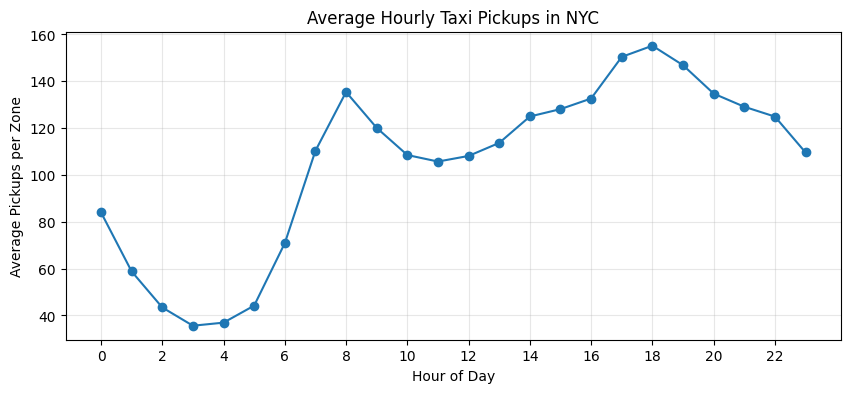

Busiest hour: 18
Average pickups per zone: 155.18


In [ ]:
import matplotlib.pyplot as plt

# Extract hour from pickup time
complete_data["hour"] = complete_data["pickup_hour"].dt.hour

# Calculate average pickups per zone for each hour
hourly_pattern = complete_data.groupby("hour")["pickup_count"].mean()

# Visualize demand by hour
plt.figure(figsize=(10, 4))
plt.plot(hourly_pattern.index, hourly_pattern.values, marker="o")

plt.title("Average Hourly Taxi Pickups in NYC")
plt.xlabel("Hour of Day")
plt.ylabel("Average Pickups per Zone")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()

print("Busiest hour:", hourly_pattern.idxmax())
print("Average pickups per zone:", round(hourly_pattern.max(), 2))

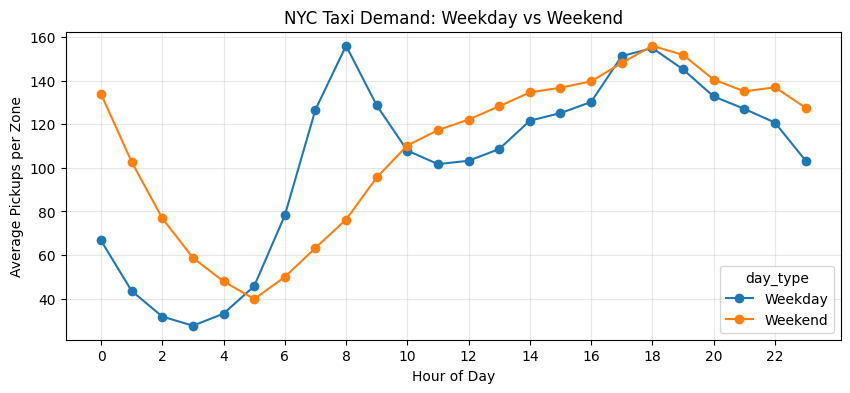

In [ ]:
# Identify weekdays and weekends
complete_data["day_of_week"] = complete_data["pickup_hour"].dt.dayofweek

complete_data["day_type"] = complete_data["day_of_week"].apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate average pickups by hour and day type
day_pattern = complete_data.groupby(
    ["hour", "day_type"]
)["pickup_count"].mean().unstack()

# Plot weekday and weekend demand
day_pattern.plot(figsize=(10, 4), marker="o")

plt.title("NYC Taxi Demand: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Average Pickups per Zone")
plt.xticks(range(0, 24, 2))
plt.grid(alpha=0.3)
plt.show()

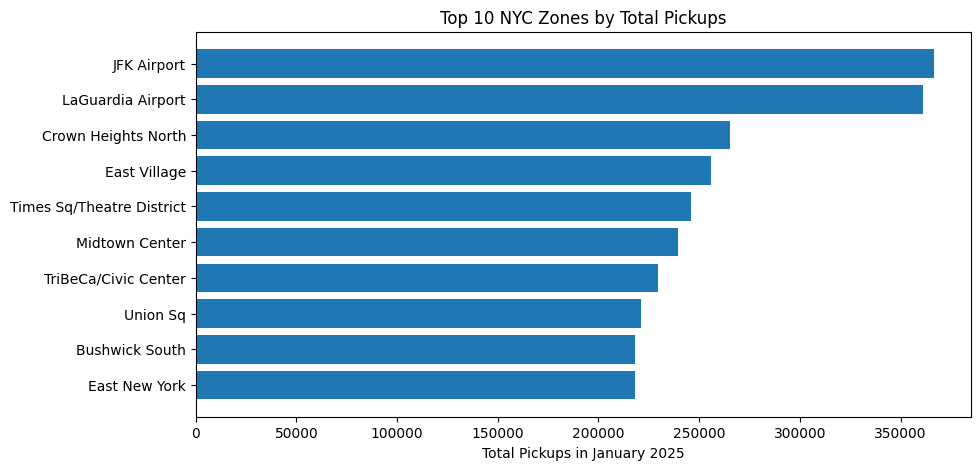

,Zone,pickup_count
130,JFK Airport,366536
136,LaGuardia Airport,361220
59,Crown Heights North,265393
77,East Village,255992
228,Times Sq/Theatre District,245839
159,Midtown Center,239287
229,TriBeCa/Civic Center,229707
232,Union Sq,221311
35,Bushwick South,218353
74,East New York,218048


In [ ]:
# Calculate total pickups for each zone
zone_demand = complete_data.groupby("zone_id")["pickup_count"].sum()

# Add zone names
zone_demand = zone_demand.reset_index().merge(
    zones[["LocationID", "Zone"]],
    left_on="zone_id",
    right_on="LocationID"
)

# Find top 10 zones
top_zones = zone_demand.nlargest(10, "pickup_count")

# Plot
plt.figure(figsize=(10, 5))
plt.barh(top_zones["Zone"], top_zones["pickup_count"])

plt.title("Top 10 NYC Zones by Total Pickups")
plt.xlabel("Total Pickups in January 2025")
plt.gca().invert_yaxis()
plt.show()

display(top_zones[["Zone", "pickup_count"]])

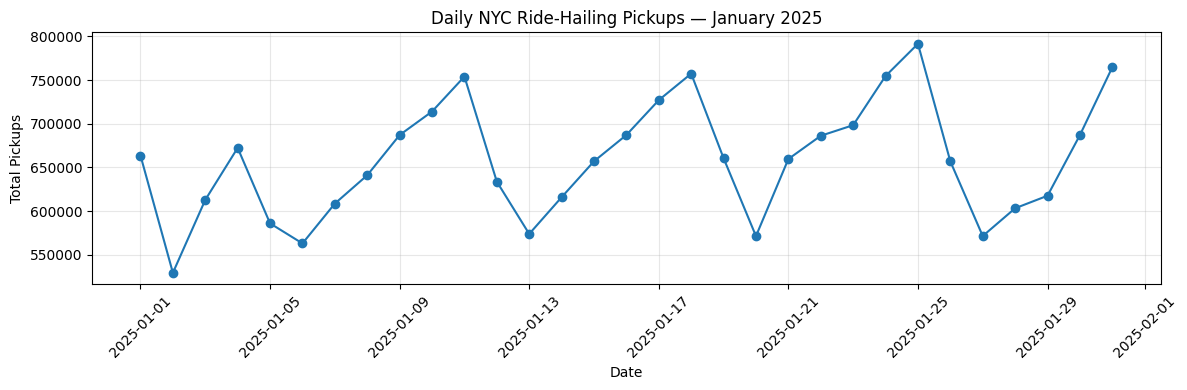

Busiest day: 2025-01-25
Pickups on busiest day: 791550
Quietest day: 2025-01-02
Pickups on quietest day: 529213


In [ ]:
# Extract the date
complete_data["date"] = complete_data["pickup_hour"].dt.date

# Calculate total pickups per day
daily_demand = complete_data.groupby("date")["pickup_count"].sum()

# Plot daily demand
plt.figure(figsize=(12, 4))
plt.plot(daily_demand.index, daily_demand.values, marker="o")

plt.title("Daily NYC Ride-Hailing Pickups — January 2025")
plt.xlabel("Date")
plt.ylabel("Total Pickups")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Busiest day:", daily_demand.idxmax())
print("Pickups on busiest day:", daily_demand.max())

print("Quietest day:", daily_demand.idxmin())
print("Pickups on quietest day:", daily_demand.min())

In [ ]:
# Create time-based features
complete_data["hour"] = complete_data["pickup_hour"].dt.hour

complete_data["day_of_week"] = complete_data["pickup_hour"].dt.dayofweek

complete_data["day_of_month"] = complete_data["pickup_hour"].dt.day

complete_data["is_weekend"] = (
    complete_data["day_of_week"] >= 5
).astype(int)

# Display our new features
display(
    complete_data[
        ["zone_id", "pickup_hour", "hour",
         "day_of_week", "day_of_month",
         "is_weekend", "pickup_count"]
    ].head()
)

,zone_id,pickup_hour,hour,day_of_week,day_of_month,is_weekend,pickup_count
0,2,2025-01-01 00:00:00,0,2,1,0,0
1,2,2025-01-01 01:00:00,1,2,1,0,0
2,2,2025-01-01 02:00:00,2,2,1,0,0
3,2,2025-01-01 03:00:00,3,2,1,0,0
4,2,2025-01-01 04:00:00,4,2,1,0,0


In [ ]:
# Sort data by zone and time
complete_data = complete_data.sort_values(
    ["zone_id", "pickup_hour"]
).reset_index(drop=True)

# Create historical demand features for each zone
complete_data["lag_1"] = complete_data.groupby("zone_id")["pickup_count"].shift(1)

complete_data["lag_24"] = complete_data.groupby("zone_id")["pickup_count"].shift(24)

complete_data["lag_168"] = complete_data.groupby("zone_id")["pickup_count"].shift(168)

# Display sample rows after 7 days
display(
    complete_data[
        ["zone_id", "pickup_hour", "pickup_count",
         "lag_1", "lag_24", "lag_168"]
    ].iloc[168:173]
)

,zone_id,pickup_hour,pickup_count,lag_1,lag_24,lag_168
168,2,2025-01-08 00:00:00,0,0.0,0.0,0.0
169,2,2025-01-08 01:00:00,0,0.0,0.0,0.0
170,2,2025-01-08 02:00:00,0,0.0,0.0,0.0
171,2,2025-01-08 03:00:00,0,0.0,0.0,0.0
172,2,2025-01-08 04:00:00,0,0.0,0.0,0.0


In [ ]:
# Use previous-hour demand to avoid data leakage
past_demand = complete_data.groupby("zone_id")["pickup_count"].shift(1)

# Calculate rolling averages separately for each zone
for window in [3, 6, 24]:
    complete_data[f"rolling_avg_{window}"] = (
        past_demand.groupby(complete_data["zone_id"])
        .transform(lambda x: x.rolling(window).mean())
    )

# Display our features
display(
    complete_data[
        ["zone_id", "pickup_hour", "pickup_count",
         "rolling_avg_3", "rolling_avg_6",
         "rolling_avg_24"]
    ].iloc[168:173]
)

,zone_id,pickup_hour,pickup_count,rolling_avg_3,rolling_avg_6,rolling_avg_24
168,2,2025-01-08 00:00:00,0,0.0,0.0,0.041667
169,2,2025-01-08 01:00:00,0,0.0,0.0,0.041667
170,2,2025-01-08 02:00:00,0,0.0,0.0,0.041667
171,2,2025-01-08 03:00:00,0,0.0,0.0,0.041667
172,2,2025-01-08 04:00:00,0,0.0,0.0,0.041667


In [ ]:
# Remove rows with missing historical features
ml_data = complete_data.dropna().copy()

# Remove the EDA-only date and day_type columns
ml_data = ml_data.drop(columns=["date", "day_type"])

# Save the ML-ready dataset
ml_file = project_path / "ml_features.parquet"
ml_data.to_parquet(ml_file, index=False)

print("Original rows:", len(complete_data))
print("ML-ready rows:", len(ml_data))
print("Missing values:", ml_data.isnull().sum().sum())
print("Total columns:", len(ml_data.columns))
print("Saved successfully:", ml_file.exists())

display(ml_data.head())

Original rows: 194928
ML-ready rows: 150912
Missing values: 0
Total columns: 13
Saved successfully: True


,zone_id,pickup_hour,pickup_count,hour,day_of_week,day_of_month,is_weekend,lag_1,lag_24,lag_168,rolling_avg_3,rolling_avg_6,rolling_avg_24
168,2,2025-01-08 00:00:00,0,0,2,8,0,0.0,0.0,0.0,0.0,0.0,0.041667
169,2,2025-01-08 01:00:00,0,1,2,8,0,0.0,0.0,0.0,0.0,0.0,0.041667
170,2,2025-01-08 02:00:00,0,2,2,8,0,0.0,0.0,0.0,0.0,0.0,0.041667
171,2,2025-01-08 03:00:00,0,3,2,8,0,0.0,0.0,0.0,0.0,0.0,0.041667
172,2,2025-01-08 04:00:00,0,4,2,8,0,0.0,0.0,0.0,0.0,0.0,0.041667


In [ ]:
# Split the dataset by date
train = ml_data[ml_data["pickup_hour"] < "2025-01-24"].copy()

val = ml_data[
    (ml_data["pickup_hour"] >= "2025-01-24") &
    (ml_data["pickup_hour"] < "2025-01-28")
].copy()

test = ml_data[ml_data["pickup_hour"] >= "2025-01-28"].copy()

# Save each dataset
train.to_parquet(project_path / "train.parquet", index=False)
val.to_parquet(project_path / "validation.parquet", index=False)
test.to_parquet(project_path / "test.parquet", index=False)

print("Training rows:", len(train))
print("Validation rows:", len(val))
print("Testing rows:", len(test))
print("Total rows:", len(train) + len(val) + len(test))

Training rows: 100608
Validation rows: 25152
Testing rows: 25152
Total rows: 150912


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual pickup counts
y_val = val["pickup_count"]

# Baseline predictions: same hour yesterday
baseline_predictions = val["lag_24"]

# Calculate errors
mae = mean_absolute_error(y_val, baseline_predictions)
rmse = np.sqrt(mean_squared_error(y_val, baseline_predictions))

print("Baseline MAE:", round(mae, 2))
print("Baseline RMSE:", round(rmse, 2))

Baseline MAE: 33.97
Baseline RMSE: 69.36


In [ ]:
# Predict using demand from the same hour last week
weekly_predictions = val["lag_168"]

# Calculate errors
weekly_mae = mean_absolute_error(y_val, weekly_predictions)
weekly_rmse = np.sqrt(mean_squared_error(y_val, weekly_predictions))

print("Yesterday Baseline MAE:", round(mae, 2))
print("Yesterday Baseline RMSE:", round(rmse, 2))

print("\nLast Week Baseline MAE:", round(weekly_mae, 2))
print("Last Week Baseline RMSE:", round(weekly_rmse, 2))

Yesterday Baseline MAE: 33.97
Yesterday Baseline RMSE: 69.36

Last Week Baseline MAE: 18.28
Last Week Baseline RMSE: 37.04


In [ ]:
# Select features used for prediction
features = [
    "zone_id", "hour", "day_of_week", "day_of_month",
    "is_weekend", "lag_1", "lag_24", "lag_168",
    "rolling_avg_3", "rolling_avg_6", "rolling_avg_24"
]

# Prepare training data
X_train = train[features]
y_train = train["pickup_count"]

# Prepare validation data
X_val = val[features]
y_val = val["pickup_count"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Number of input features:", len(features))

Training features: (100608, 11)
Validation features: (25152, 11)
Number of input features: 11


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=60,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict validation demand
rf_predictions = rf_model.predict(X_val)

# Calculate errors
rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Weekly Baseline MAE:", round(weekly_mae, 2))

Random Forest MAE: 15.49
Random Forest RMSE: 29.71
Weekly Baseline MAE: 18.28


In [ ]:
%pip install -q xgboost

from xgboost import XGBRegressor

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train, y_train)

# Predict validation demand
xgb_predictions = xgb_model.predict(X_val)

# Calculate errors
xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))

print("XGBoost MAE:", round(xgb_mae, 2))
print("XGBoost RMSE:", round(xgb_rmse, 2))
print("Random Forest MAE:", round(rf_mae, 2))
print("Weekly Baseline MAE:", round(weekly_mae, 2))

XGBoost MAE: 14.93
XGBoost RMSE: 28.87
Random Forest MAE: 15.49
Weekly Baseline MAE: 18.28


In [ ]:
# Predict on training data
train_predictions = xgb_model.predict(X_train)

# Calculate training error
train_mae = mean_absolute_error(y_train, train_predictions)

# Compare training and validation errors
print("Training MAE:", round(train_mae, 2))
print("Validation MAE:", round(xgb_mae, 2))
print("Difference:", round(xgb_mae - train_mae, 2))

Training MAE: 9.9
Validation MAE: 14.93
Difference: 5.03


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Get unique training hours in chronological order
hours = train["pickup_hour"].sort_values().unique()

# Create 3 chronological validation folds
tscv = TimeSeriesSplit(n_splits=3, test_size=48)

cv_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(hours), 1):

    # Select complete hours for each fold
    train_hours = hours[train_idx]
    val_hours = hours[val_idx]

    train_mask = train["pickup_hour"].isin(train_hours)
    val_mask = train["pickup_hour"].isin(val_hours)

    # Train a fresh XGBoost model
    model = clone(xgb_model)
    model.fit(X_train.loc[train_mask], y_train.loc[train_mask])

    # Evaluate on future hours
    predictions = model.predict(X_train.loc[val_mask])
    score = mean_absolute_error(y_train.loc[val_mask], predictions)

    cv_scores.append(score)
    print(f"Fold {fold} MAE: {score:.2f}")

print("\nAverage CV MAE:", round(np.mean(cv_scores), 2))

Fold 1 MAE: 13.53
Fold 2 MAE: 15.36
Fold 3 MAE: 12.11

Average CV MAE: 13.67


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Reuse chronological folds from Step 23
cv_splits = []

for train_idx, val_idx in tscv.split(hours):
    train_hours = hours[train_idx]
    val_hours = hours[val_idx]

    train_rows = np.where(train["pickup_hour"].isin(train_hours))[0]
    val_rows = np.where(train["pickup_hour"].isin(val_hours))[0]

    cv_splits.append((train_rows, val_rows))

# Hyperparameters to explore
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1]
}

# Find the best combination using time-aware CV
search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=6,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=1
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print("Best CV MAE:", round(-search.best_score_, 2))

Best Parameters: {'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.05}
Best CV MAE: 13.4


In [ ]:
# Get the best model from hyperparameter tuning
tuned_model = search.best_estimator_

# Predict on our separate validation dataset
tuned_predictions = tuned_model.predict(X_val)

# Calculate validation errors
tuned_mae = mean_absolute_error(y_val, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_val, tuned_predictions))

print("Original XGBoost MAE:", round(xgb_mae, 2))
print("Tuned XGBoost MAE:", round(tuned_mae, 2))

print("\nOriginal XGBoost RMSE:", round(xgb_rmse, 2))
print("Tuned XGBoost RMSE:", round(tuned_rmse, 2))

Original XGBoost MAE: 14.93
Tuned XGBoost MAE: 15.01

Original XGBoost RMSE: 28.87
Tuned XGBoost RMSE: 29.18


In [ ]:
import joblib

# Select the model with the lowest validation MAE
best_model = xgb_model if xgb_mae <= tuned_mae else tuned_model

# Save the selected model permanently
model_file = project_path / "best_xgboost.pkl"
joblib.dump(best_model, model_file)

print("Selected model:", "Original XGBoost" if xgb_mae <= tuned_mae else "Tuned XGBoost")
print("Best Validation MAE:", round(min(xgb_mae, tuned_mae), 2))
print("Model saved:", model_file.exists())

Selected model: Original XGBoost
Best Validation MAE: 14.93
Model saved: True


In [ ]:
from sklearn.metrics import r2_score

# Prepare test data
X_test = test[features]
y_test = test["pickup_count"]

# Predict future hourly pickups
test_predictions = best_model.predict(X_test)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

test_wape = (
    np.abs(y_test - test_predictions).sum()
    / y_test.sum() * 100
)

print("Final Test Results")
print("MAE:", round(test_mae, 2))
print("RMSE:", round(test_rmse, 2))
print("R²:", round(test_r2, 4))
print("WAPE:", round(test_wape, 2), "%")

print("\nWeekly Baseline Test MAE:",
      round(mean_absolute_error(y_test, test["lag_168"]), 2))

Final Test Results
MAE: 11.66
RMSE: 21.17
R²: 0.967
WAPE: 10.98 %

Weekly Baseline Test MAE: 14.46


In [ ]:
# Create a table with actual and predicted pickups
results = test[["zone_id", "pickup_hour", "pickup_count"]].copy()

results["predicted_count"] = np.maximum(test_predictions, 0)

# Calculate absolute prediction errors
results["absolute_error"] = abs(
    results["pickup_count"] - results["predicted_count"]
)

# Calculate average error for each zone
zone_errors = results.groupby("zone_id")["absolute_error"].mean().reset_index()

# Add NYC zone names
zone_errors = zone_errors.merge(
    zones[["LocationID", "Zone"]],
    left_on="zone_id",
    right_on="LocationID"
)

# Display the 10 zones with the largest average errors
worst_zones = zone_errors.nlargest(10, "absolute_error")

display(worst_zones[["Zone", "absolute_error"]])

,Zone,absolute_error
136,LaGuardia Airport,86.440089
130,JFK Airport,74.318129
159,Midtown Center,39.258773
160,Midtown East,32.083519
77,East Village,30.283222
244,West Chelsea/Hudson Yards,30.022888
232,Union Sq,29.507165
66,East Chelsea,28.874337
229,TriBeCa/Civic Center,27.498072
59,Crown Heights North,27.086049


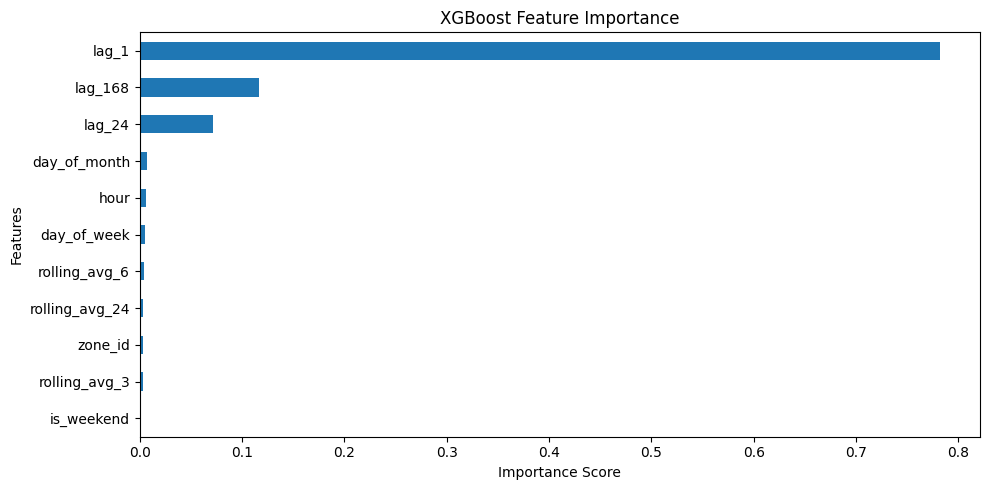

Top 3 Important Features:
lag_1      0.781939
lag_168    0.116492
lag_24     0.071147
dtype: float32


In [ ]:
# Get feature importance scores
importance = pd.Series(
    best_model.feature_importances_,
    index=features
).sort_values()

# Plot feature importance
plt.figure(figsize=(10, 5))
importance.plot(kind="barh")

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# Display the three most important features
print("Top 3 Important Features:")
print(importance.tail(3).sort_values(ascending=False))

In [ ]:
# Prepare predictions for fleet allocation
fleet_data = results[
    ["zone_id", "pickup_hour", "pickup_count", "predicted_count"]
].copy()

# Save predictions to Google Drive
prediction_file = project_path / "test_predictions.parquet"
fleet_data.to_parquet(prediction_file, index=False)

print("Prediction records:", len(fleet_data))
print("Total predicted pickups:", round(fleet_data["predicted_count"].sum()))
print("Total actual pickups:", fleet_data["pickup_count"].sum())
print("Saved successfully:", prediction_file.exists())

display(fleet_data.head())

Prediction records: 25152
Total predicted pickups: 2729644
Total actual pickups: 2672235
Saved successfully: True


,zone_id,pickup_hour,pickup_count,predicted_count
648,2,2025-01-28 00:00:00,0,0.000000
649,2,2025-01-28 01:00:00,0,0.000000
650,2,2025-01-28 02:00:00,0,0.000000
651,2,2025-01-28 03:00:00,0,0.000000
652,2,2025-01-28 04:00:00,0,0.366669


In [ ]:
# Choose one hour from the test period
selected_hour = pd.Timestamp("2025-01-28 18:00:00")

# Get demand predictions for all zones at that hour
hour_data = fleet_data[
    fleet_data["pickup_hour"] == selected_hour
].copy()

# Round predictions to whole pickups
hour_data["predicted_count"] = (
    hour_data["predicted_count"].round().astype(int)
)

print("Selected hour:", selected_hour)
print("Number of zones:", len(hour_data))
print("Total predicted pickups:", hour_data["predicted_count"].sum())
print("Total actual pickups:", hour_data["pickup_count"].sum())

display(hour_data.head())

Selected hour: 2025-01-28 18:00:00
Number of zones: 262
Total predicted pickups: 40148
Total actual pickups: 38753


,zone_id,pickup_hour,pickup_count,predicted_count
666,2,2025-01-28 18:00:00,0,0
1410,3,2025-01-28 18:00:00,67,102
2154,4,2025-01-28 18:00:00,78,86
2898,5,2025-01-28 18:00:00,8,7
3642,6,2025-01-28 18:00:00,19,17


In [ ]:
# Total hypothetical available taxis
total_taxis = 30000

# Create a reproducible random generator
rng = np.random.default_rng(42)

# Distribute half the taxis based on predicted demand
demand_weights = (
    hour_data["predicted_count"].to_numpy() + 1
)
demand_weights = demand_weights / demand_weights.sum()

# Distribute the other half unevenly across zones
random_weights = rng.dirichlet(np.ones(len(hour_data)))

# Combine both distributions
fleet_weights = 0.5 * demand_weights + 0.5 * random_weights

# Allocate all 30,000 taxis
hour_data["available_taxis"] = rng.multinomial(
    total_taxis, fleet_weights
)

print("Total available taxis:", hour_data["available_taxis"].sum())
print("Total predicted pickups:", hour_data["predicted_count"].sum())

display(
    hour_data[
        ["zone_id", "predicted_count", "available_taxis"]
    ].head()
)

Total available taxis: 30000
Total predicted pickups: 40148


,zone_id,predicted_count,available_taxis
666,2,0,149
1410,3,102,180
2154,4,86,171
2898,5,7,13
3642,6,17,12


In [ ]:
# Calculate predicted taxi shortages
hour_data["shortage"] = (
    hour_data["predicted_count"] - hour_data["available_taxis"]
).clip(lower=0)

# Calculate surplus taxis
hour_data["surplus"] = (
    hour_data["available_taxis"] - hour_data["predicted_count"]
).clip(lower=0)

print("Zones with shortages:", (hour_data["shortage"] > 0).sum())
print("Zones with surplus taxis:", (hour_data["surplus"] > 0).sum())

print("Total predicted shortage:", hour_data["shortage"].sum())
print("Total surplus taxis:", hour_data["surplus"].sum())

display(
    hour_data[
        ["zone_id", "predicted_count", "available_taxis",
         "shortage", "surplus"]
    ].head()
)

Zones with shortages: 160
Zones with surplus taxis: 100
Total predicted shortage: 15740
Total surplus taxis: 5592


,zone_id,predicted_count,available_taxis,shortage,surplus
666,2,0,149,0,149
1410,3,102,180,0,78
2154,4,86,171,0,85
2898,5,7,13,0,6
3642,6,17,12,5,0


In [ ]:
import requests
import zipfile

# Official NYC taxi zone boundaries
map_url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip"

zip_file = project_path / "taxi_zones.zip"
map_folder = project_path / "taxi_zones"

# Download only if needed
if not zip_file.exists():
    response = requests.get(map_url, timeout=120)
    response.raise_for_status()
    zip_file.write_bytes(response.content)

# Extract the map files
map_folder.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(map_folder)

print("Map downloaded:", zip_file.exists())
print("Map files extracted:", len(list(map_folder.iterdir())))
print("Shapefile available:", any(map_folder.glob("*.shp")))

Map downloaded: True
Map files extracted: 1
Shapefile available: False


In [ ]:
# Search all subfolders for the shapefile
shapefiles = list(map_folder.rglob("*.shp"))

print("Shapefiles found:", len(shapefiles))
print("Shapefile locations:", shapefiles)

Shapefiles found: 1
Shapefile locations: [PosixPath('/content/drive/MyDrive/RideOpt_AI_v2/taxi_zones/taxi_zones/taxi_zones.shp')]


In [ ]:
import geopandas as gpd

# Load the NYC taxi zone map
taxi_map = gpd.read_file(shapefiles[0])

# Convert coordinates to a system measured in meters
taxi_map = taxi_map.to_crs(epsg=32618)

# Calculate the center of each zone
taxi_map["center"] = taxi_map.geometry.centroid

# Extract center coordinates
taxi_map["x"] = taxi_map["center"].x
taxi_map["y"] = taxi_map["center"].y

# Keep only the information we need
zone_centers = taxi_map[["LocationID", "x", "y"]].copy()

# Save for future use
center_file = project_path / "zone_centers.parquet"
zone_centers.to_parquet(center_file, index=False)

print("Zone centers calculated:", len(zone_centers))
print("Saved successfully:", center_file.exists())

display(zone_centers.head())

Zone centers calculated: 263
Saved successfully: True


,LocationID,x,y
0,1,569790.647079,4.504876e+06
1,2,598857.689392,4.496870e+06
2,3,597132.830783,4.524352e+06
3,4,586397.447762,4.508595e+06
4,5,568709.395372,4.489416e+06


In [ ]:
from scipy.spatial.distance import cdist

# Keep centers for the 262 NYC zones
nyc_centers = zone_centers[
    zone_centers["LocationID"].isin(valid_zones)
].copy()

# Arrange centers in the same order as our fleet data
nyc_centers = nyc_centers.set_index("LocationID").loc[
    hour_data["zone_id"]
]

# Calculate straight-line distances in kilometers
coordinates = nyc_centers[["x", "y"]].to_numpy()

distance_matrix = cdist(coordinates, coordinates) / 1000

print("Distance matrix shape:", distance_matrix.shape)
print("Distance from first zone to itself:", distance_matrix[0, 0])
print("Example distance between first two zones:",
      round(distance_matrix[0, 1], 2), "km")

Distance matrix shape: (262, 262)
Distance from first zone to itself: 0.0
Example distance between first two zones: 27.54 km


In [ ]:
# Copy shortages and surpluses so the original data stays unchanged
shortages = hour_data["shortage"].to_numpy().copy()
surpluses = hour_data["surplus"].to_numpy().copy()

# Maximum allowed straight-line repositioning distance
max_distance = 5.0

# Find valid moves: surplus zone to shortage zone within 5 km
possible_moves = []

for i in range(len(hour_data)):
    for j in range(len(hour_data)):
        if surpluses[i] > 0 and shortages[j] > 0:
            if 0 < distance_matrix[i, j] <= max_distance:
                possible_moves.append((distance_matrix[i, j], i, j))

# Prioritize shorter distances
possible_moves.sort()

# Allocate taxis greedily
movements = []

for distance, i, j in possible_moves:
    taxis_to_move = min(surpluses[i], shortages[j])

    if taxis_to_move > 0:
        surpluses[i] -= taxis_to_move
        shortages[j] -= taxis_to_move

        movements.append({
            "from_zone": int(hour_data.iloc[i]["zone_id"]),
            "to_zone": int(hour_data.iloc[j]["zone_id"]),
            "taxis_moved": int(taxis_to_move),
            "distance_km": round(float(distance), 2)
        })

# Convert movements into a table
movements_df = pd.DataFrame(movements)

print("Repositioning routes:", len(movements_df))
print("Total taxis moved:", movements_df["taxis_moved"].sum())

display(movements_df.head())

Repositioning routes: 140
Total taxis moved: 4531


,from_zone,to_zone,taxis_moved,distance_km
0,88,12,1,0.35
1,24,151,61,0.50
2,88,87,28,0.51
3,211,144,6,0.51
4,54,52,1,0.53


In [ ]:
# Original taxi availability
before = hour_data.set_index("zone_id")["available_taxis"].copy()

# Taxi availability after repositioning
after = before.copy()

for move in movements:
    after.loc[move["from_zone"]] -= move["taxis_moved"]
    after.loc[move["to_zone"]] += move["taxis_moved"]

# Actual recorded pickups
actual = hour_data.set_index("zone_id")["pickup_count"]

# Calculate simulated pickups covered
covered_before = np.minimum(actual, before).sum()
covered_after = np.minimum(actual, after).sum()

# Calculate improvement
improvement = (covered_after - covered_before) / covered_before * 100

# Calculate total repositioning distance
total_distance = sum(
    move["taxis_moved"] * move["distance_km"]
    for move in movements
)

print("Pickups covered before:", covered_before)
print("Pickups covered after:", covered_after)
print("Additional pickups covered:", covered_after - covered_before)
print("Simulated improvement:", round(improvement, 2), "%")
print("Total repositioning distance:", round(total_distance, 2), "vehicle-km")
print("Fleet size unchanged:", after.sum() == before.sum())

Pickups covered before: 24154
Pickups covered after: 27760
Additional pickups covered: 3606
Simulated improvement: 14.93 %
Total repositioning distance: 8654.01 vehicle-km
Fleet size unchanged: True


In [ ]:
# Get last week's pickup counts for the same hour
baseline_data = test[
    test["pickup_hour"] == selected_hour
][["zone_id", "lag_168"]].copy()

# Match the baseline to our fleet data
baseline_data = hour_data[["zone_id"]].merge(
    baseline_data,
    on="zone_id",
    how="left"
)

baseline_data["baseline_demand"] = (
    baseline_data["lag_168"].round().astype(int)
)

print("Zones:", len(baseline_data))
print("Total weekly baseline demand:", baseline_data["baseline_demand"].sum())

display(baseline_data.head())

Zones: 262
Total weekly baseline demand: 42172


,zone_id,lag_168,baseline_demand
0,2,1.0,1
1,3,124.0,124
2,4,101.0,101
3,5,7.0,7
4,6,13.0,13


In [ ]:
# Function to simulate fleet repositioning
def evaluate_allocation(demand):
    supply = hour_data["available_taxis"].to_numpy().copy()

    shortage = np.maximum(demand - supply, 0)
    surplus = np.maximum(supply - demand, 0)

    # Find nearby surplus-to-shortage routes
    routes = [
        (distance_matrix[i, j], i, j)
        for i in range(len(supply))
        for j in range(len(supply))
        if surplus[i] > 0 and shortage[j] > 0
        and 0 < distance_matrix[i, j] <= 5
    ]

    # Move taxis along the shortest routes first
    for distance, i, j in sorted(routes):
        moved = min(surplus[i], shortage[j])

        supply[i] -= moved
        supply[j] += moved

        surplus[i] -= moved
        shortage[j] -= moved

    # Evaluate using actual recorded pickups
    actual = hour_data["pickup_count"].to_numpy()

    return np.minimum(actual, supply).sum()


# Compare both strategies
ml_covered = evaluate_allocation(
    hour_data["predicted_count"].to_numpy()
)

baseline_covered = evaluate_allocation(
    baseline_data["baseline_demand"].to_numpy()
)

print("Without repositioning:", covered_before)
print("Weekly baseline allocation:", baseline_covered)
print("XGBoost allocation:", ml_covered)
print("ML advantage:", ml_covered - baseline_covered)

Without repositioning: 24154
Weekly baseline allocation: 27591
XGBoost allocation: 27760
ML advantage: 169


In [ ]:
# Create a fleet distribution independent of both forecasts
rng = np.random.default_rng(123)

# Randomly distribute taxis across NYC zones
independent_weights = rng.dirichlet(
    np.ones(len(hour_data))
)

independent_taxis = rng.multinomial(
    30000, independent_weights
)

# Replace the original simulated fleet
hour_data["available_taxis"] = independent_taxis

print("Total taxis:", hour_data["available_taxis"].sum())
print("Zones with taxis:", (hour_data["available_taxis"] > 0).sum())

display(
    hour_data[
        ["zone_id", "available_taxis"]
    ].head()
)

Total taxis: 30000
Zones with taxis: 261


,zone_id,available_taxis
666,2,72
1410,3,10
2154,4,29
2898,5,33
3642,6,10


In [ ]:
# Actual recorded pickups
actual = hour_data["pickup_count"].to_numpy()

# Coverage without moving any taxis
no_move_covered = np.minimum(
    actual,
    hour_data["available_taxis"].to_numpy()
).sum()

# Coverage using last week's demand
weekly_covered = evaluate_allocation(
    baseline_data["baseline_demand"].to_numpy()
)

# Coverage using XGBoost predictions
ml_covered = evaluate_allocation(
    hour_data["predicted_count"].to_numpy()
)

# Compare results
print("No repositioning:", no_move_covered)
print("Weekly baseline:", weekly_covered)
print("XGBoost:", ml_covered)

print("\nML vs no repositioning:",
      round((ml_covered / no_move_covered - 1) * 100, 2), "%")

print("ML vs weekly baseline:",
      round((ml_covered / weekly_covered - 1) * 100, 2), "%")

No repositioning: 17091
Weekly baseline: 24493
XGBoost: 24836

ML vs no repositioning: 45.32 %
ML vs weekly baseline: 1.4 %


In [ ]:
# Save our current fleet
original_fleet = hour_data["available_taxis"].copy()

simulation_results = []

for seed in range(20):

    rng = np.random.default_rng(seed)

    weights = rng.dirichlet(np.ones(len(hour_data)))

    hour_data["available_taxis"] = rng.multinomial(
        30000, weights
    )

    # Evaluate both strategies on the same fleet
    weekly = evaluate_allocation(
        baseline_data["baseline_demand"].to_numpy()
    )

    ml = evaluate_allocation(
        hour_data["predicted_count"].to_numpy()
    )

    simulation_results.append({
        "seed": seed,
        "weekly_covered": weekly,
        "ml_covered": ml,
        "ml_advantage": ml - weekly
    })

# Restore our original fleet
hour_data["available_taxis"] = original_fleet

simulation_df = pd.DataFrame(simulation_results)

print("Simulations:", len(simulation_df))
print("Average ML advantage:",
      round(simulation_df["ml_advantage"].mean(), 2))

print("ML wins:",
      (simulation_df["ml_advantage"] > 0).sum())

print("Weekly baseline wins:",
      (simulation_df["ml_advantage"] < 0).sum())

display(simulation_df.head())

Simulations: 20
Average ML advantage: 332.5
ML wins: 20
Weekly baseline wins: 0


,seed,weekly_covered,ml_covered,ml_advantage
0,0,24505,24734,229
1,1,24412,24842,430
2,2,24794,25269,475
3,3,25124,25520,396
4,4,25420,25790,370


In [ ]:
# Save our current hour data
saved_hour_data = hour_data.copy()

simulation_results_24h = []

# Evaluate all 24 hours of January 28
for hour in pd.date_range("2025-01-28", periods=24, freq="h"):

    # Get predictions and actual pickups for this hour
    hour_data = fleet_data[
        fleet_data["pickup_hour"] == hour
    ].sort_values("zone_id").copy()

    hour_data["predicted_count"] = (
        hour_data["predicted_count"].round().astype(int)
    )

    # Get last week's demand for the same zones and hour
    weekly_demand = test[
        test["pickup_hour"] == hour
    ].sort_values("zone_id")["lag_168"].to_numpy().astype(int)

    actual = hour_data["pickup_count"].to_numpy()

    # Test 3 different hypothetical starting fleets
    for seed in range(3):

        rng = np.random.default_rng(seed + hour.hour * 100)
        weights = rng.dirichlet(np.ones(len(hour_data)))

        hour_data["available_taxis"] = rng.multinomial(
            30000, weights
        )

        supply = hour_data["available_taxis"].to_numpy()

        no_move = np.minimum(actual, supply).sum()
        weekly = evaluate_allocation(weekly_demand)
        ml = evaluate_allocation(
            hour_data["predicted_count"].to_numpy()
        )

        simulation_results_24h.append({
            "hour": hour,
            "seed": seed,
            "no_move": no_move,
            "weekly": weekly,
            "xgboost": ml
        })

# Restore our original hour data
hour_data = saved_hour_data

comparison_df = pd.DataFrame(simulation_results_24h)

print("Total simulations:", len(comparison_df))
print("XGBoost wins:", (comparison_df["xgboost"] > comparison_df["weekly"]).sum())
print("Weekly baseline wins:", (comparison_df["weekly"] > comparison_df["xgboost"]).sum())
print("Ties:", (comparison_df["weekly"] == comparison_df["xgboost"]).sum())

print("\nAverage pickups covered per simulation:")
print(comparison_df[["no_move", "weekly", "xgboost"]].mean().round(2))

Total simulations: 72
XGBoost wins: 64
Weekly baseline wins: 8
Ties: 0

Average pickups covered per simulation:
no_move    13127.79
weekly     18831.47
xgboost    19064.71
dtype: float64


In [ ]:
# Save all simulation comparisons
simulation_file = project_path / "fleet_simulation_results.csv"

comparison_df.to_csv(simulation_file, index=False)

print("Simulation records saved:", len(comparison_df))
print("File saved successfully:", simulation_file.exists())

# Calculate average improvements
avg_results = comparison_df[
    ["no_move", "weekly", "xgboost"]
].mean()

ml_vs_no_move = (
    (avg_results["xgboost"] / avg_results["no_move"]) - 1
) * 100

ml_vs_weekly = (
    (avg_results["xgboost"] / avg_results["weekly"]) - 1
) * 100

print("\nXGBoost vs No Repositioning:",
      round(ml_vs_no_move, 2), "%")

print("XGBoost vs Weekly Baseline:",
      round(ml_vs_weekly, 2), "%")

Simulation records saved: 72
File saved successfully: True

XGBoost vs No Repositioning: 45.22 %
XGBoost vs Weekly Baseline: 1.24 %


In [ ]:
# Evaluate pickup coverage and repositioning distance
def evaluate_with_distance(demand):
    supply = hour_data["available_taxis"].to_numpy().copy()

    shortage = np.maximum(demand - supply, 0)
    surplus = np.maximum(supply - demand, 0)

    routes = [
        (distance_matrix[i, j], i, j)
        for i in range(len(supply))
        for j in range(len(supply))
        if surplus[i] > 0 and shortage[j] > 0
        and 0 < distance_matrix[i, j] <= 5
    ]

    taxis_moved = 0
    total_distance = 0

    for distance, i, j in sorted(routes):
        moved = min(surplus[i], shortage[j])

        supply[i] -= moved
        supply[j] += moved
        surplus[i] -= moved
        shortage[j] -= moved

        taxis_moved += moved
        total_distance += moved * distance

    actual = hour_data["pickup_count"].to_numpy()
    covered = np.minimum(actual, supply).sum()

    return covered, taxis_moved, total_distance


# Compare both forecasting strategies
weekly_result = evaluate_with_distance(
    baseline_data["baseline_demand"].to_numpy()
)

ml_result = evaluate_with_distance(
    hour_data["predicted_count"].to_numpy()
)

print("Weekly baseline:", tuple(round(x, 2) for x in weekly_result))
print("XGBoost:", tuple(round(x, 2) for x in ml_result))
print("\nFormat: (pickups covered, taxis moved, vehicle-km)")

Weekly baseline: (np.int64(24493), np.int64(8701), np.float64(15825.51))
XGBoost: (np.int64(24836), np.int64(8826), np.float64(15965.78))

Format: (pickups covered, taxis moved, vehicle-km)


In [ ]:
# Compare XGBoost against the weekly baseline
extra_pickups = ml_result[0] - weekly_result[0]

extra_taxis = ml_result[1] - weekly_result[1]

extra_distance = ml_result[2] - weekly_result[2]

# Additional pickups per 100 vehicle-km
efficiency = extra_pickups / extra_distance * 100

print("Additional pickups covered:", extra_pickups)
print("Additional taxis moved:", extra_taxis)
print("Additional distance:", round(extra_distance, 2), "vehicle-km")

print("Extra pickups per 100 additional vehicle-km:",
      round(efficiency, 2))

Additional pickups covered: 343
Additional taxis moved: 125
Additional distance: 140.26 vehicle-km
Extra pickups per 100 additional vehicle-km: 244.54


In [ ]:
# Assumed average repositioning speed
average_speed = 20  # km per hour

# Maximum time allowed for repositioning
max_time = 10  # minutes

# Calculate maximum travel distance
max_travel_distance = average_speed * (max_time / 60)

print("Assumed average speed:", average_speed, "km/h")
print("Maximum repositioning time:", max_time, "minutes")
print("Maximum travel distance:",
      round(max_travel_distance, 2), "km")

Assumed average speed: 20 km/h
Maximum repositioning time: 10 minutes
Maximum travel distance: 3.33 km


In [ ]:
# Update our allocation function to accept a distance limit
def evaluate_with_distance(demand, max_distance=5):
    supply = hour_data["available_taxis"].to_numpy().copy()

    shortage = np.maximum(demand - supply, 0)
    surplus = np.maximum(supply - demand, 0)

    routes = [
        (distance_matrix[i, j], i, j)
        for i in range(len(supply))
        for j in range(len(supply))
        if surplus[i] > 0 and shortage[j] > 0
        and 0 < distance_matrix[i, j] <= max_distance
    ]

    taxis_moved = 0
    total_distance = 0

    for distance, i, j in sorted(routes):
        moved = min(surplus[i], shortage[j])

        supply[i] -= moved
        supply[j] += moved
        surplus[i] -= moved
        shortage[j] -= moved

        taxis_moved += moved
        total_distance += moved * distance

    actual = hour_data["pickup_count"].to_numpy()
    covered = np.minimum(actual, supply).sum()

    return covered, taxis_moved, total_distance


# Compare both methods under the new distance limit
weekly_10min = evaluate_with_distance(
    baseline_data["baseline_demand"].to_numpy(),
    max_travel_distance
)

ml_10min = evaluate_with_distance(
    hour_data["predicted_count"].to_numpy(),
    max_travel_distance
)

print("Weekly baseline:", tuple(round(x, 2) for x in weekly_10min))
print("XGBoost:", tuple(round(x, 2) for x in ml_10min))

print("\nFormat: (pickups covered, taxis moved, vehicle-km)")

Weekly baseline: (np.int64(23861), np.int64(7895), np.float64(12444.09))
XGBoost: (np.int64(24172), np.int64(7991), np.float64(12508.11))

Format: (pickups covered, taxis moved, vehicle-km)


In [ ]:
# Compare both distance limits using XGBoost
result_5km = evaluate_with_distance(
    hour_data["predicted_count"].to_numpy(),
    5
)

result_3km = evaluate_with_distance(
    hour_data["predicted_count"].to_numpy(),
    max_travel_distance
)

# Create comparison table
distance_comparison = pd.DataFrame({
    "Distance Limit": ["5 km", "3.33 km"],
    "Pickups Covered": [result_5km[0], result_3km[0]],
    "Taxis Moved": [result_5km[1], result_3km[1]],
    "Vehicle-km": [result_5km[2], result_3km[2]]
})

display(distance_comparison.round(2))

# Calculate percentage reduction in travel
travel_reduction = (
    1 - result_3km[2] / result_5km[2]
) * 100

print("Travel distance reduced by:",
      round(travel_reduction, 2), "%")

print("Difference in pickups covered:",
      result_5km[0] - result_3km[0])

,Distance Limit,Pickups Covered,Taxis Moved,Vehicle-km
0,5 km,24836,8826,15965.78
1,3.33 km,24172,7991,12508.11


Travel distance reduced by: 21.66 %
Difference in pickups covered: 664


In [ ]:
# Save our current hour data
saved_hour_data = hour_data.copy()

results_10min = []

for hour in pd.date_range("2025-01-28", periods=24, freq="h"):

    # Select the current hour
    hour_data = fleet_data[
        fleet_data["pickup_hour"] == hour
    ].sort_values("zone_id").copy()

    hour_data["predicted_count"] = (
        hour_data["predicted_count"].round().astype(int)
    )

    weekly_demand = test[
        test["pickup_hour"] == hour
    ].sort_values("zone_id")["lag_168"].to_numpy().astype(int)

    # Use 3 identical fleet scenarios for both strategies
    for seed in range(3):

        rng = np.random.default_rng(seed + hour.hour * 100)
        weights = rng.dirichlet(np.ones(len(hour_data)))

        hour_data["available_taxis"] = rng.multinomial(
            30000, weights
        )

        weekly = evaluate_with_distance(
            weekly_demand, max_travel_distance
        )

        ml = evaluate_with_distance(
            hour_data["predicted_count"].to_numpy(),
            max_travel_distance
        )

        results_10min.append({
            "hour": hour,
            "seed": seed,
            "weekly_covered": weekly[0],
            "ml_covered": ml[0],
            "weekly_distance": weekly[2],
            "ml_distance": ml[2]
        })

# Restore our original hour data
hour_data = saved_hour_data

results_10min = pd.DataFrame(results_10min)

print("Total simulations:", len(results_10min))
print("XGBoost wins:",
      (results_10min["ml_covered"] > results_10min["weekly_covered"]).sum())
print("Weekly baseline wins:",
      (results_10min["weekly_covered"] > results_10min["ml_covered"]).sum())

print("\nAverage results:")
display(results_10min[
    ["weekly_covered", "ml_covered",
     "weekly_distance", "ml_distance"]
].mean().round(2))

Total simulations: 72
XGBoost wins: 61
Weekly baseline wins: 11

Average results:


,0
weekly_covered,18204.33
ml_covered,18384.83
weekly_distance,9832.10
ml_distance,9703.27


In [ ]:
# Save our 72 simulation results
final_simulation_file = project_path / "distance_constrained_results.csv"

results_10min.to_csv(final_simulation_file, index=False)

# Calculate average improvements
coverage_gain = (
    results_10min["ml_covered"].mean()
    / results_10min["weekly_covered"].mean() - 1
) * 100

distance_change = (
    results_10min["ml_distance"].mean()
    / results_10min["weekly_distance"].mean() - 1
) * 100

print("Results saved:", final_simulation_file.exists())
print("Total simulations:", len(results_10min))
print("XGBoost coverage improvement:", round(coverage_gain, 2), "%")
print("XGBoost distance change:", round(distance_change, 2), "%")

Results saved: True
Total simulations: 72
XGBoost coverage improvement: 0.99 %
XGBoost distance change: -1.31 %


In [ ]:
# Save current hour data
saved_hour_data = hour_data.copy()

limit_results = []

for hour in pd.date_range("2025-01-28", periods=24, freq="h"):

    hour_data = fleet_data[
        fleet_data["pickup_hour"] == hour
    ].sort_values("zone_id").copy()

    hour_data["predicted_count"] = (
        hour_data["predicted_count"].round().astype(int)
    )

    for seed in range(3):
        rng = np.random.default_rng(seed + hour.hour * 100)
        weights = rng.dirichlet(np.ones(len(hour_data)))

        hour_data["available_taxis"] = rng.multinomial(
            30000, weights
        )

        # Evaluate XGBoost under both distance limits
        result_5 = evaluate_with_distance(
            hour_data["predicted_count"].to_numpy(), 5
        )

        result_3 = evaluate_with_distance(
            hour_data["predicted_count"].to_numpy(),
            max_travel_distance
        )

        limit_results.append({
            "hour": hour,
            "seed": seed,
            "coverage_5km": result_5[0],
            "coverage_3km": result_3[0],
            "distance_5km": result_5[2],
            "distance_3km": result_3[2]
        })

# Restore original data
hour_data = saved_hour_data

limit_df = pd.DataFrame(limit_results)

print("Total scenarios:", len(limit_df))

print("\nAverage results:")
display(
    limit_df[
        ["coverage_5km", "coverage_3km",
         "distance_5km", "distance_3km"]
    ].mean().round(2)
)

Total scenarios: 72

Average results:


,0
coverage_5km,19064.71
coverage_3km,18384.83
distance_5km,13006.50
distance_3km,9703.27


In [ ]:
# Save all 72 simulation comparisons
limit_file = project_path / "distance_limit_comparison.csv"
limit_df.to_csv(limit_file, index=False)

# Calculate average coverage and distance
avg_5km_coverage = limit_df["coverage_5km"].mean()
avg_3km_coverage = limit_df["coverage_3km"].mean()

avg_5km_distance = limit_df["distance_5km"].mean()
avg_3km_distance = limit_df["distance_3km"].mean()

# Calculate percentage reductions
coverage_reduction = (
    1 - avg_3km_coverage / avg_5km_coverage
) * 100

distance_reduction = (
    1 - avg_3km_distance / avg_5km_distance
) * 100

print("Coverage reduction:", round(coverage_reduction, 2), "%")
print("Travel distance reduction:", round(distance_reduction, 2), "%")
print("File saved successfully:", limit_file.exists())

Coverage reduction: 3.57 %
Travel distance reduction: 25.4 %
File saved successfully: True


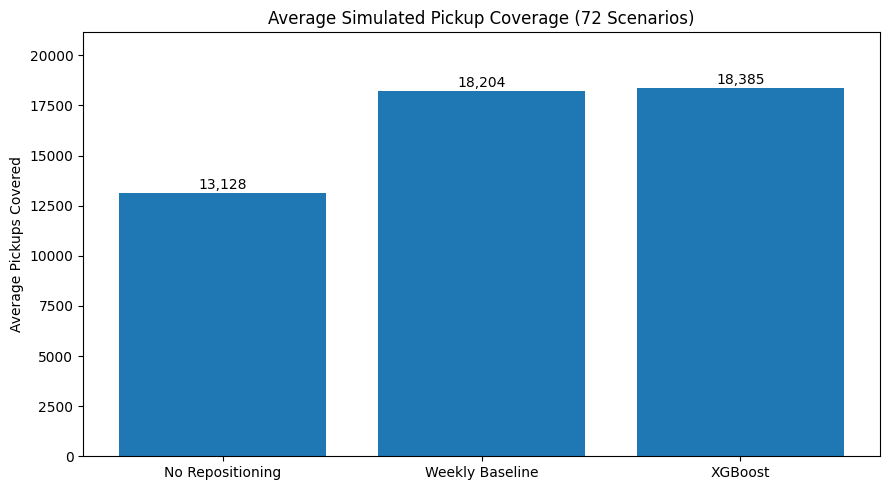

In [ ]:
# Calculate average coverage for each strategy
avg_no_move = comparison_df["no_move"].mean()

avg_weekly = results_10min["weekly_covered"].mean()

avg_xgboost = results_10min["ml_covered"].mean()

# Create comparison chart
strategies = [
    "No Repositioning",
    "Weekly Baseline",
    "XGBoost"
]

coverage = [avg_no_move, avg_weekly, avg_xgboost]

plt.figure(figsize=(9, 5))
bars = plt.bar(strategies, coverage)

# Display values above bars
for bar, value in zip(bars, coverage):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{value:,.0f}",
        ha="center"
    )

plt.title("Average Simulated Pickup Coverage (72 Scenarios)")
plt.ylabel("Average Pickups Covered")
plt.ylim(0, max(coverage) * 1.15)
plt.tight_layout()
plt.show()

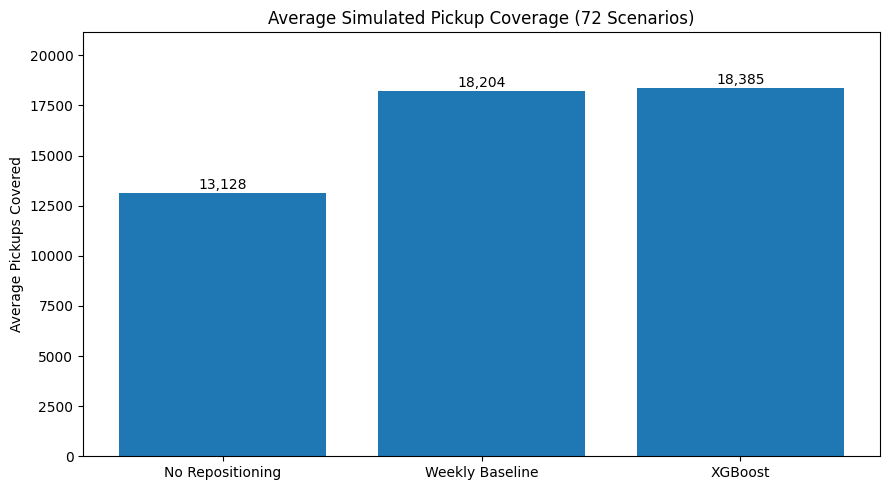

Chart saved successfully: True


In [ ]:
# Recreate and save our comparison chart
plt.figure(figsize=(9, 5))

bars = plt.bar(strategies, coverage)

for bar, value in zip(bars, coverage):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 200,
        f"{value:,.0f}",
        ha="center"
    )

plt.title("Average Simulated Pickup Coverage (72 Scenarios)")
plt.ylabel("Average Pickups Covered")
plt.ylim(0, max(coverage) * 1.15)
plt.tight_layout()

# Save chart permanently
chart_file = project_path / "fleet_coverage_comparison.png"
plt.savefig(chart_file, dpi=150, bbox_inches="tight")

plt.show()

print("Chart saved successfully:", chart_file.exists())

In [ ]:
# Create a folder for our Streamlit application
app_folder = project_path / "app"
app_folder.mkdir(exist_ok=True)

# Check the files our app will need
required_files = [
    "best_xgboost.pkl",
    "test_predictions.parquet",
    "taxi_zone_lookup.csv",
    "distance_constrained_results.csv",
    "fleet_coverage_comparison.png"
]

for filename in required_files:
    file_path = project_path / filename
    print(filename, "✅" if file_path.exists() else "❌")

print("\nApp folder created:", app_folder.exists())

best_xgboost.pkl ✅
test_predictions.parquet ✅
taxi_zone_lookup.csv ✅
distance_constrained_results.csv ✅
fleet_coverage_comparison.png ✅

App folder created: True


In [ ]:
# Create the Streamlit app file
app_file = app_folder / "app.py"

app_code = '''
import streamlit as st
import pandas as pd
from pathlib import Path

# Project folder
project_path = Path(__file__).resolve().parent.parent

# Page settings
st.set_page_config(
    page_title="RideOpt AI",
    page_icon="🚕",
    layout="wide"
)

# Dashboard title
st.title("🚕 RideOpt AI")
st.write("NYC Ride-Hailing Demand Prediction & Fleet Allocation")

st.divider()

# Machine Learning results
st.header("Machine Learning Performance")

col1, col2, col3 = st.columns(3)

col1.metric("Test MAE", "11.66")
col2.metric("Test R²", "0.967")
col3.metric("Test WAPE", "10.98%")

# Fleet allocation results
st.header("Fleet Allocation Simulation")

st.image(
    str(project_path / "fleet_coverage_comparison.png"),
    caption="Average simulated pickup coverage across 72 scenarios"
)

st.info(
    "Fleet allocation results are simulated using hypothetical "
    "vehicle availability and straight-line distances."
)
'''

# Save the application
app_file.write_text(app_code, encoding="utf-8")

print("Streamlit app created:", app_file.exists())
print("App location:", app_file)

Streamlit app created: True
App location: /content/drive/MyDrive/RideOpt_AI_v2/app/app.py


In [ ]:
%pip install -q streamlit

import subprocess
import sys
import time
from google.colab import output

# Start Streamlit
streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        str(app_file),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=open("/tmp/rideopt_streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

# Get browser link
app_url = output.eval_js("google.colab.kernel.proxyPort(8501)")

print("Streamlit process running:", streamlit_process.poll() is None)
print("Open your dashboard:", app_url)

Streamlit process running: True
Open your dashboard: https://8501-m-s-usc1a2-70eia8ldauc3-a.us-central1.prod.r.colab.dev


In [ ]:
import requests

# Check whether Streamlit is responding
try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )

    print("Streamlit HTTP status:", response.status_code)
    print("Server response:", response.text)

except Exception as e:
    print("Connection error:", e)

# Show recent Streamlit logs
print("\nStreamlit logs:")
with open("/tmp/rideopt_streamlit.log") as f:
    print(f.read()[-2000:])

Streamlit HTTP status: 200
Server response: ok

Streamlit logs:
Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1a2-70eia8ldauc3-a.us-central1.prod.r.colab.dev, host=m-s-usc1a2-70eia8ldauc3.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-11-17 15:44:11.657 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1a2-70eia8ldauc3-a.us-central1.prod.r.colab.dev, host=m-s-usc1a2-70eia8ldauc3.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-11-17 15:44:16.241 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1a2-70eia8ldauc3-a.us-central1.prod.r.colab.dev, host=m-s-usc1a2-70eia8ldauc3.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-11-17 15:44:20.964 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1a2-70eia8ldauc3-a.us-central1.prod.r.colab.dev, host=m-s-usc1a2-70eia8ldauc3.us

In [ ]:
# Stop the previous Streamlit process
streamlit_process.terminate()
streamlit_process.wait()

# Restart with Colab-compatible settings
streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        str(app_file),
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=open("/tmp/rideopt_streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit running:", streamlit_process.poll() is None)
print("Dashboard link:", output.eval_js(
    "google.colab.kernel.proxyPort(8501)"
))

Streamlit running: True
Dashboard link: https://8501-m-s-usc1a2-70eia8ldauc3-a.us-central1.prod.r.colab.dev


In [ ]:
# Read our existing Streamlit application
app_code = app_file.read_text(encoding="utf-8")

# Add a sidebar menu
menu_code = '''
# Sidebar navigation
page = st.sidebar.radio(
    "Navigation",
    ["Overview", "Demand Prediction"]
)

'''

# Insert navigation before the dashboard
app_code = app_code.replace(
    '# Dashboard title',
    menu_code + '# Dashboard title'
)

# Add our prediction section
prediction_code = '''
# Interactive demand prediction
if page == "Demand Prediction":

    st.header("Predict NYC Taxi Demand")

    predictions = pd.read_parquet(
        project_path / "test_predictions.parquet"
    )

    zones = pd.read_csv(
        project_path / "taxi_zone_lookup.csv"
    )

    zone_names = dict(zip(zones["LocationID"], zones["Zone"]))

    selected_zone = st.selectbox(
        "Select NYC Taxi Zone",
        sorted(predictions["zone_id"].unique()),
        format_func=lambda z: zone_names.get(z, str(z))
    )

    zone_data = predictions[
        predictions["zone_id"] == selected_zone
    ].copy()

    st.line_chart(
        zone_data.set_index("pickup_hour")[
            ["pickup_count", "predicted_count"]
        ]
    )

    st.caption(
        "Actual vs predicted hourly pickups on held-out "
        "January 28–31, 2025 data."
    )
'''

# Append the prediction section
if 'if page == "Demand Prediction":' not in app_code:
    app_code += prediction_code

# Save changes
app_file.write_text(app_code, encoding="utf-8")

print("Demand Prediction page added successfully!")

Demand Prediction page added successfully!


In [ ]:
# Read our existing app
app_code = app_file.read_text(encoding="utf-8")

# Separate Overview from Demand Prediction
app_code = app_code.replace(
    '# Machine Learning results',
    'if page == "Overview":\n\n    # Machine Learning results'
)

# Indent Overview code until the prediction section
start = app_code.index('    # Machine Learning results')
end = app_code.index('# Interactive demand prediction')

overview_code = app_code[start:end]

# Indent all Overview lines by 4 more spaces,
# except the first comment which is already indented
lines = overview_code.splitlines()
fixed_lines = [lines[0]] + [
    "    " + line if line.strip() else line
    for line in lines[1:]
]

app_code = (
    app_code[:start]
    + "\n".join(fixed_lines)
    + "\n\n"
    + app_code[end:]
)

# Save updated app
app_file.write_text(app_code, encoding="utf-8")

print("Page navigation updated successfully!")

Page navigation updated successfully!


In [ ]:
# Read our Streamlit application
app_code = app_file.read_text(encoding="utf-8")

# Add date selection before displaying the graph
old_code = '''    st.line_chart(
        zone_data.set_index("pickup_hour")[
            ["pickup_count", "predicted_count"]
        ]
    )'''

new_code = '''    # Select a date
    selected_date = st.selectbox(
        "Select Date",
        sorted(zone_data["pickup_hour"].dt.date.unique())
    )

    # Show only the selected date
    zone_data = zone_data[
        zone_data["pickup_hour"].dt.date == selected_date
    ]

    st.line_chart(
        zone_data.set_index("pickup_hour")[
            ["pickup_count", "predicted_count"]
        ]
    )'''

# Apply the change once
if old_code in app_code:
    app_code = app_code.replace(old_code, new_code)
    app_file.write_text(app_code, encoding="utf-8")
    print("Date filter added successfully!")
else:
    print("Date filter already added or code not found.")

Date filter added successfully!


In [ ]:
# Read our existing Streamlit app
app_code = app_file.read_text(encoding="utf-8")

# Add hourly details after the line chart
hourly_code = '''
    # Select an hour to inspect
    selected_hour = st.selectbox(
        "Select Hour",
        range(24),
        format_func=lambda h: f"{h:02d}:00"
    )

    # Find the selected hour's prediction
    selected_row = zone_data[
        zone_data["pickup_hour"].dt.hour == selected_hour
    ].iloc[0]

    predicted = selected_row["predicted_count"]
    actual = selected_row["pickup_count"]

    col1, col2, col3 = st.columns(3)

    col1.metric("Predicted Pickups", f"{predicted:.0f}")
    col2.metric("Actual Pickups", f"{actual:.0f}")
    col3.metric("Absolute Error", f"{abs(actual - predicted):.1f}")
'''

# Insert before the existing caption
marker = '    st.caption(\n        "Actual vs predicted hourly pickups'

if 'selected_hour = st.selectbox(' not in app_code:
    app_code = app_code.replace(
        marker,
        hourly_code + '\n' + marker
    )
    app_file.write_text(app_code, encoding="utf-8")
    print("Hourly prediction details added successfully!")
else:
    print("Hourly prediction feature already exists.")

Hourly prediction details added successfully!


In [ ]:
# Read our existing Streamlit app
app_code = app_file.read_text(encoding="utf-8")

# Add Fleet Allocation to the navigation menu
app_code = app_code.replace(
    '["Overview", "Demand Prediction"]',
    '["Overview", "Demand Prediction", "Fleet Allocation"]'
)

# Create the Fleet Allocation page
fleet_page = '''
# Fleet Allocation page
if page == "Fleet Allocation":

    st.header("Fleet Allocation Simulation")

    st.write(
        "Compare simulated taxi allocation strategies "
        "using a 3.33 km repositioning limit."
    )

    # Load saved simulation results
    fleet_results = pd.read_csv(
        project_path / "distance_constrained_results.csv"
    )

    # Calculate average performance
    summary = pd.DataFrame({
        "Strategy": ["Weekly Baseline", "XGBoost"],
        "Average Pickups Covered": [
            fleet_results["weekly_covered"].mean(),
            fleet_results["ml_covered"].mean()
        ],
        "Average Vehicle-km": [
            fleet_results["weekly_distance"].mean(),
            fleet_results["ml_distance"].mean()
        ]
    })

    st.dataframe(summary.round(2), hide_index=True)

    st.caption(
        "Results are based on 72 independent hypothetical "
        "hourly fleet scenarios, not real NYC vehicle movements."
    )
'''

# Add the page only once
if 'if page == "Fleet Allocation":' not in app_code:
    app_code += "\n" + fleet_page

# Save updated app
app_file.write_text(app_code, encoding="utf-8")

print("Fleet Allocation page added successfully!")

# Check Python syntax
compile(app_code, str(app_file), "exec")
print("No Python syntax errors!")

Fleet Allocation page added successfully!
No Python syntax errors!


In [ ]:
# Read existing Streamlit code
app_code = app_file.read_text(encoding="utf-8")

# Chart code
chart_code = '''
    # Compare pickup coverage visually
    st.subheader("Pickup Coverage Comparison")

    chart_data = summary.set_index("Strategy")[
        "Average Pickups Covered"
    ]

    st.bar_chart(chart_data)

'''

# Insert chart after the summary table
marker = '    st.dataframe(summary.round(2), hide_index=True)'

if 'st.bar_chart(chart_data)' not in app_code:
    app_code = app_code.replace(
        marker,
        marker + "\n" + chart_code
    )
    app_file.write_text(app_code, encoding="utf-8")
    print("Fleet comparison chart added successfully!")
else:
    print("Chart already exists.")

# Verify syntax
compile(app_code, str(app_file), "exec")
print("No Python syntax errors!")

Fleet comparison chart added successfully!
No Python syntax errors!


In [ ]:
# Read existing Streamlit app
app_code = app_file.read_text(encoding="utf-8")

# Add another chart to Fleet Allocation
distance_chart_code = '''
    # Compare repositioning distance
    st.subheader("Repositioning Distance Comparison")

    distance_data = summary.set_index("Strategy")[
        "Average Vehicle-km"
    ]

    st.bar_chart(distance_data)

    st.caption(
        "Lower vehicle-km means less simulated "
        "empty repositioning travel."
    )

'''

# Insert before Fleet Allocation disclaimer
marker = '''    st.caption(
        "Results are based on 72 independent hypothetical'''

if 'st.bar_chart(distance_data)' not in app_code:
    app_code = app_code.replace(
        marker,
        distance_chart_code + marker
    )

    app_file.write_text(app_code, encoding="utf-8")
    print("Distance comparison chart added successfully!")
else:
    print("Distance comparison chart already exists.")

# Check Python syntax
compile(app_code, str(app_file), "exec")
print("No Python syntax errors!")

Distance comparison chart added successfully!
No Python syntax errors!


In [ ]:
# Read the existing Streamlit app
app_code = app_file.read_text(encoding="utf-8")

metrics_code = '''
    # Calculate improvements
    coverage_gain = (
        summary.loc[1, "Average Pickups Covered"]
        / summary.loc[0, "Average Pickups Covered"] - 1
    ) * 100

    distance_reduction = (
        1 - summary.loc[1, "Average Vehicle-km"]
        / summary.loc[0, "Average Vehicle-km"]
    ) * 100

    col1, col2 = st.columns(2)

    col1.metric(
        "Simulated Pickup Coverage Gain",
        f"+{coverage_gain:.2f}%"
    )

    col2.metric(
        "Repositioning Distance Reduction",
        f"{distance_reduction:.2f}%"
    )

'''

# Insert metrics before the comparison table
marker = '    st.dataframe(summary.round(2), hide_index=True)'

if 'Simulated Pickup Coverage Gain' not in app_code:
    app_code = app_code.replace(
        marker,
        metrics_code + marker
    )
    app_file.write_text(app_code, encoding="utf-8")
    print("Fleet performance metrics added successfully!")
else:
    print("Metrics already exist.")

compile(app_code, str(app_file), "exec")
print("No Python syntax errors!")

Fleet performance metrics added successfully!
No Python syntax errors!
